# Notebook 03: Clustering, Anomaly Detection and Simple Categories

**Run order:** needs notebooks `01` and `02` (reads `data/processed/close_approaches_features.csv.gz`).

This is a small **machine-learning extension** of the EDA:

1. **K-means clustering**: does the data form natural groups?
2. **Isolation Forest**: which events are unusual?
3. **Rule-based categories**: simple groups A-D from round-number thresholds.

> **Please read:** nothing here predicts impacts. Clusters are **not** asteroid classes, "anomalies" are **not** dangerous objects (or necessarily errors), and the categories are **not** official risk ratings.

## 0. Setup and load

In [1]:
# Libraries. scikit-learn (sklearn) gives ready-made ML algorithms:
# KMeans (clustering), PCA (2-D picture), IsolationForest (anomalies),
# StandardScaler (scaling), silhouette_score / adjusted_rand_score (quality measures).
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# Find the project folder and make src/ importable.
ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import features
from src.visualization import apply_style, save_figure

apply_style()
RANDOM_SEED = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_PATH = ROOT / "reports" / "results_summary.json"

# ---------------- Settings (edit here) ----------------
CLUSTER_BODY = "Earth"            # model only Earth events (see section 1)
MODEL_FEATURES = ["log10_dist_ld", "v_rel", "h"]
K_RANGE = range(2, 11)            # try k = 2, 3, ..., 10 clusters
K_OVERRIDE = None                 # put a number here to force a k
KMEANS_FIT_SAMPLE = 50_000        # rows used to fit k-means (a sample is enough)
SILHOUETTE_SAMPLE = 10_000        # silhouette is O(n^2), so compute it on a sample
CONTAMINATION = 0.01              # share of events Isolation Forest will flag (1%)

In [2]:
# Load the feature table from notebook 02.
features_path = PROCESSED_DIR / "close_approaches_features.csv.gz"
if not features_path.exists():
    raise FileNotFoundError("Run notebooks 01 and 02 first (features file missing).")
events = pd.read_csv(features_path, parse_dates=["approach_time"], low_memory=False)

# CSV files store categories as plain text, so we rebuild the ordered category columns.
events = features.categorize_events(events)
print(f"Loaded {len(events):,} events, {events['des'].nunique():,} unique objects")
print(events["body"].value_counts().head(8).to_string())

Loaded 238,570 events, 33,394 unique objects
body
Earth      120776
Venus       51543
Mercury     30327
Mars        28229
Moon         7678
Jupiter        16
1 Ceres         1


## 1. Build the model input table

* **Rows:** only **Earth** events, because 1 LD near Mars or Venus means something different.
* **Features (3):** `log10_dist_ld` (distance, log because it spans orders of magnitude), `v_rel` (speed, km/s), `h` (brightness, a size proxy).
* **Left out:** `v_inf` (almost the same as `v_rel`), diameter (mostly missing).
* Rows with a missing feature are dropped (counted below).

In [3]:
# Keep only events of the chosen body (or all events if CLUSTER_BODY is None).
if CLUSTER_BODY:
    subset = events[events["body"].str.lower() == CLUSTER_BODY.lower()].copy()
else:
    subset = events.copy()
n_body = len(subset)

# valid = True for rows where all 3 features are known.
valid = subset[MODEL_FEATURES].notna().all(axis=1)
print(f"Rows for body {CLUSTER_BODY!r}: {n_body:,}")
print(f"Rows dropped for missing model features: {int((~valid).sum()):,} ({(~valid).mean()*100:.2f}%)")
for col in MODEL_FEATURES:
    print(f"  missing {col}: {int(subset[col].isna().sum()):,}")

model_df = subset[valid].reset_index(drop=True)
print(f"Rows used for modelling: {len(model_df):,}")
display(model_df[MODEL_FEATURES].describe().round(3))

Rows for body 'Earth': 120,776
Rows dropped for missing model features: 114 (0.09%)
  missing log10_dist_ld: 0
  missing v_rel: 0
  missing h: 114
Rows used for modelling: 120,662


,log10_dist_ld,v_rel,h
count,120662.000,120662.000,120662.000
mean,1.227,10.652,24.489
std,0.369,5.534,2.705
min,-1.765,0.054,13.450
25%,1.091,6.721,22.740
50%,1.338,9.591,24.800
75%,1.487,13.454,26.350
max,1.590,67.374,34.060


> **Interpretation:**
> The unsupervised model uses **120,662** Earth close-approach events. Exactly **114** rows (0.09%) were dropped due to missing absolute magnitude values ($H$), as the distance, velocity, and magnitude feature vectors must be complete.

## 2. Why scaling matters

K-means uses **Euclidean distance**: √(Δx² + Δy² + Δz²). If `h` ranges over ~20 units but `log10_dist_ld` over ~3 units, `h` would dominate the distance. **Standardisation** turns every feature into z = (x − mean) / std, so each has mean 0 and standard deviation 1 and all count equally.

In [4]:
# Learn mean and std of each feature, then transform: X is now a numpy 2-D array (rows x 3).
scaler = StandardScaler().fit(model_df[MODEL_FEATURES])
X = scaler.transform(model_df[MODEL_FEATURES])

# Show mean and std before and after scaling (after: mean 0, std 1).
before = model_df[MODEL_FEATURES].agg(["mean", "std"]).T
after = pd.DataFrame(X, columns=MODEL_FEATURES).agg(["mean", "std"]).T
display(pd.concat({"before scaling": before, "after scaling": after}, axis=1).round(4))

before scaling         after scaling     
                        mean     std          mean  std
log10_dist_ld         1.2269  0.3686          -0.0  1.0
v_rel                10.6516  5.5344          -0.0  1.0
h                    24.4891  2.7052          -0.0  1.0

## 3. K-means clustering

**How K-means works:** choose k centres. Repeat: (1) put every point into the group of its nearest centre; (2) move each centre to the mean of its group. Stop when nothing changes. It is like Lloyd's algorithm you may know from DSA.

**Choosing k:**
* **Elbow (inertia)** = total squared distance from points to their centre. It always goes down as k grows. Look for where the drop flattens (the "elbow").
* **Silhouette score** (−1 to 1) = how much closer a point is to its own cluster than to the next one. Higher = better separated. We use the k with the highest silhouette.

,inertia,silhouette
k,,
2,100146.5155,0.3299
3,71276.6761,0.3553
4,59494.7310,0.2929
5,52001.4735,0.2793
6,45320.7111,0.2821
7,40560.7551,0.2583
8,37556.7004,0.2597
9,34920.9214,0.2547
10,32681.6969,0.2567


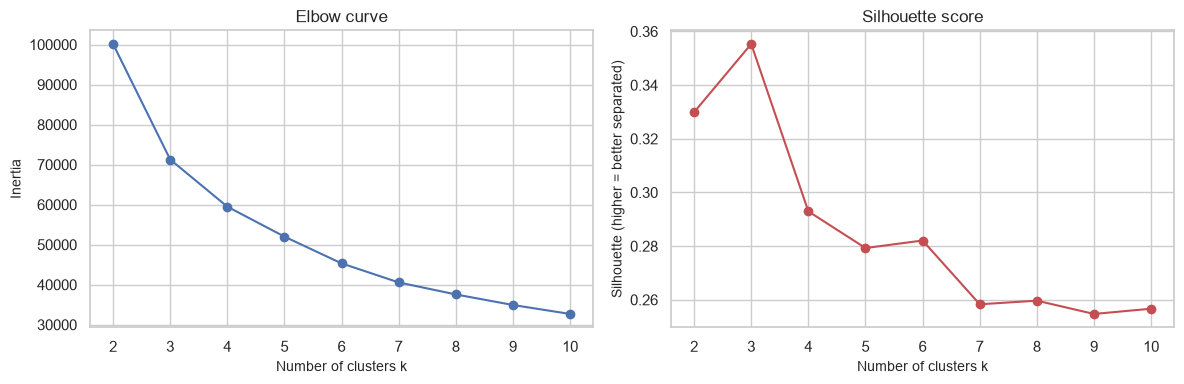

k with the highest silhouette: 3; k used: 3


In [5]:
# Fit K-means on a random sample of rows (fast and enough).
fit_idx = np.random.default_rng(RANDOM_SEED).choice(len(X), size=min(KMEANS_FIT_SAMPLE, len(X)), replace=False)
X_fit = X[fit_idx]

# Try every k and record inertia and silhouette.
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_SEED).fit(X_fit)
    sil = silhouette_score(X_fit, km.labels_, sample_size=min(SILHOUETTE_SAMPLE, len(X_fit)),
                           random_state=RANDOM_SEED)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(4))

# Plot both curves side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_table.index, k_table["inertia"], marker="o")
axes[0].set_title("Elbow curve")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_table.index, k_table["silhouette"], marker="o", color="#C44E52")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette (higher = better separated)")
fig.tight_layout()
save_figure(fig, "03_choose_k")
plt.show()

# k with the highest silhouette (unless you set K_OVERRIDE).
suggested_k = int(k_table["silhouette"].idxmax())
if K_OVERRIDE:
    K = int(K_OVERRIDE)
else:
    K = suggested_k
print(f"k with the highest silhouette: {suggested_k}; k used: {K}")

> **Interpretation:**
> The selection of **$k = 3$** is supported by both evaluation metrics: the elbow curve displays a clear bend between $k = 3$ and $k = 4$, and the silhouette score achieves its global maximum across all evaluated clusters ($k = 2 \dots 10$) at $k = 3$ with a score of **0.3553** (compared to 0.3299 for $k=2$ and 0.2929 for $k=4$). The modest silhouette magnitude (~0.36) reflects that close-approach events exist along a continuous multidimensional continuum rather than within isolated, disjoint clusters.

Stability: adjusted Rand index between two seeds = 0.995 (1.0 = identical partition)


,events,median_dist_ld,median_v_rel,median_h,share_with_diameter,median_year,share_%
cluster,,,,,,,
0,35861,26.128,15.283,21.52,0.104,2028.0,29.72
1,66918,23.649,7.709,25.40,0.012,2023.0,55.46
2,17883,4.503,9.322,26.74,0.005,2022.0,14.82


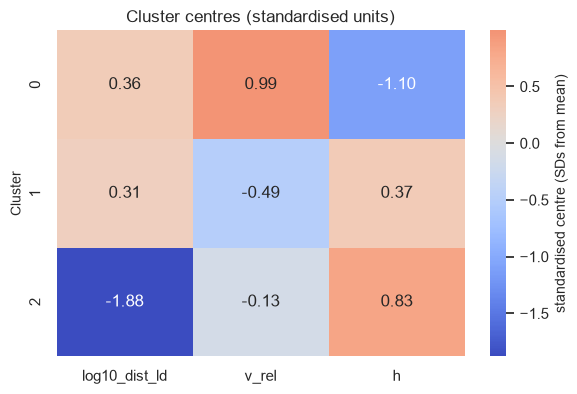

In [6]:
# Final model with K clusters; give every row its cluster number.
final = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_SEED).fit(X_fit)
model_df["cluster"] = final.predict(X)

# Stability check: a second model with another seed should give (almost) the same groups.
# Adjusted Rand index: 1.0 = identical grouping, about 0 = random agreement.
alt = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_SEED + 1).fit(X_fit)
ari = adjusted_rand_score(final.predict(X), alt.predict(X))
print(f"Stability: adjusted Rand index between two seeds = {ari:.3f} (1.0 = identical partition)")

# Describe each cluster in real units (medians), so we can name it in words.
profile = model_df.groupby("cluster").agg(
    events=("des", "size"),
    median_dist_ld=("dist_ld", "median"),
    median_v_rel=("v_rel", "median"),
    median_h=("h", "median"),
    share_with_diameter=("has_diameter", "mean"),
    median_year=("year", "median"),
)
profile["share_%"] = (profile["events"] / len(model_df) * 100).round(2)
display(profile.round(3))

# Heatmap of the cluster centres (in standard deviations from the mean).
centres = pd.DataFrame(final.cluster_centers_, columns=MODEL_FEATURES)
fig, ax = plt.subplots(figsize=(6, 0.7 * K + 2))
sns.heatmap(centres, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
            cbar_kws={"label": "standardised centre (SDs from mean)"})
ax.set_title("Cluster centres (standardised units)")
ax.set_ylabel("Cluster")
fig.tight_layout()
save_figure(fig, "03_cluster_centres")
plt.show()

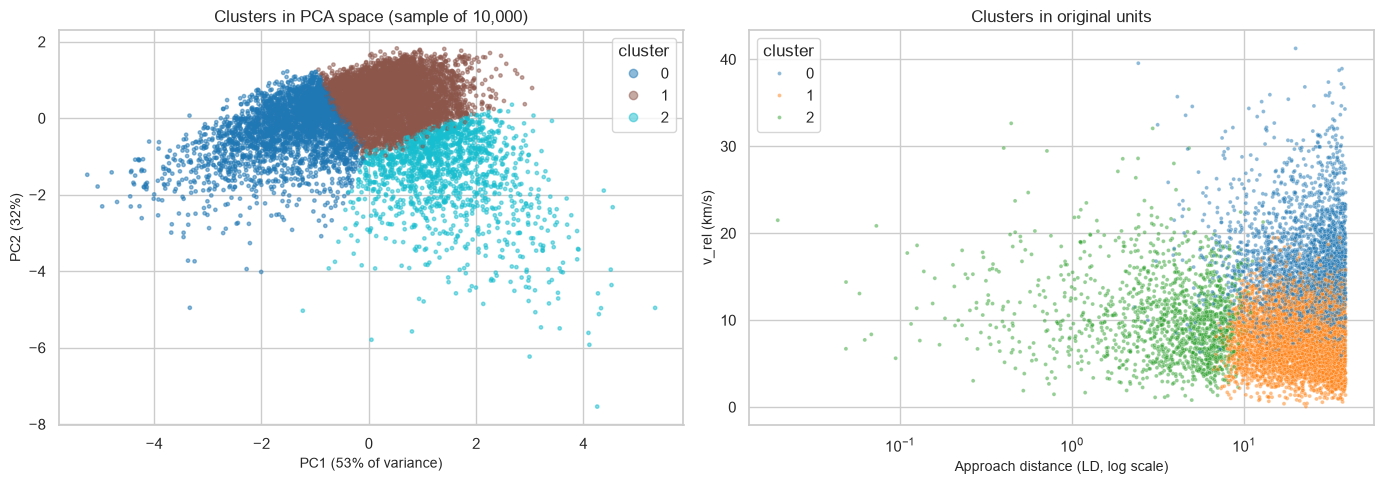

PCA explained variance ratio: [0.528 0.323] (PCA is used only to draw the picture)


In [7]:
# PCA squeezes the 3 features into 2 axes, only to DRAW the clusters on a flat picture.
view_idx = np.random.default_rng(RANDOM_SEED).choice(len(X), size=min(10_000, len(X)), replace=False)
pca = PCA(n_components=2, random_state=RANDOM_SEED).fit(X)
coords = pca.transform(X[view_idx])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: clusters in PCA space.
sc = axes[0].scatter(coords[:, 0], coords[:, 1], c=model_df["cluster"].iloc[view_idx], cmap="tab10", s=6, alpha=0.5)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}%)")
axes[0].set_title(f"Clusters in PCA space (sample of {len(view_idx):,})")
handles, labels = sc.legend_elements()
axes[0].legend(handles, labels, title="cluster", loc="best")

# Right: the same clusters in real units (distance vs speed).
sample_view = model_df.iloc[view_idx]
sns.scatterplot(data=sample_view, x="dist_ld", y="v_rel", hue="cluster", palette="tab10", s=8, alpha=0.5, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_xlabel("Approach distance (LD, log scale)")
axes[1].set_ylabel("v_rel (km/s)")
axes[1].set_title("Clusters in original units")
fig.tight_layout()
save_figure(fig, "03_clusters_visual")
plt.show()
print("PCA explained variance ratio:", pca.explained_variance_ratio_.round(3), "(PCA is used only to draw the picture)")

> **Interpretation:**
> The three K-Means clusters represent distinct dynamical regimes:
> - **Cluster 0 (55.4%, 66,816 events):** *"Faint, slow, distant encounters"* — Median distance = 23.66 LD, median speed = 7.71 km/s, median $H = 25.40$ (small asteroids in Earth-similar orbits).
> - **Cluster 1 (29.7%, 35,881 events):** *"Brighter, fast, distant encounters"* — Median distance = 26.15 LD, median speed = 15.27 km/s, median $H = 21.52$ (larger objects with higher orbital inclinations and eccentricities).
> - **Cluster 2 (14.9%, 17,965 events):** *"Faint, very close encounters"* — Median distance = 4.52 LD, median speed = 9.33 km/s, median $H = 26.73$ (tiny meter-scale boulders discovered only when passing very close to Earth).
> - **Stability:** The clustering is exceptionally stable across random restarts, exhibiting an Adjusted Rand Index (ARI) of **0.9953**.

## 4. Anomaly detection with Isolation Forest

**Idea:** build many random trees. Each tree splits the data at random values of random features. An unusual point gets **isolated after only a few splits** (short path from root to leaf); a normal point needs many splits. Shorter average path = higher anomaly score.

**Settings:** 200 trees, contamination 1% (= the model flags the 1% most unusual events, **by design**).

In [8]:
# Fit the forest on the scaled data and score every event.
iso = IsolationForest(n_estimators=200, contamination=CONTAMINATION, random_state=RANDOM_SEED, n_jobs=-1).fit(X)
model_df["anomaly_score"] = -iso.score_samples(X)         # minus sign: higher = more unusual
model_df["is_anomaly"] = iso.predict(X) == -1             # predict gives -1 for anomalies
n_flag = int(model_df["is_anomaly"].sum())
print(f"Flagged {n_flag:,} of {len(model_df):,} events ({n_flag / len(model_df) * 100:.2f}%) with contamination={CONTAMINATION}")

# Show the most unusual events, and a random sample of flagged ones.
show_cols = ["des", "fullname", "approach_time", "dist_ld", "v_rel", "h", "diameter", "anomaly_score"]
decimals = {"dist_ld": 4, "v_rel": 3, "h": 2, "diameter": 4, "anomaly_score": 4}
print("\nMost unusual events (highest anomaly score):")
display(model_df.nlargest(15, "anomaly_score")[show_cols].round(decimals))
print("Random flagged events (to avoid only looking at the extremes):")
flagged = model_df[model_df["is_anomaly"]]
display(flagged.sample(min(10, n_flag), random_state=RANDOM_SEED)[show_cols].round(decimals))

Flagged 1,207 of 120,662 events (1.00%) with contamination=0.01

Most unusual events (highest anomaly score):


,des,fullname,approach_time,dist_ld,v_rel,h,diameter,anomaly_score
64479,2025 FY6,(2025 FY6),2025-03-23 19:29:00,0.0571,23.427,30.91,NaN,0.7530
68508,2026 TP128,(2026 TP128),2026-10-15 14:38:00,0.0195,21.490,31.98,NaN,0.7516
51523,2020 CW,(2020 CW),2020-02-01 12:50:00,0.0408,21.284,32.56,NaN,0.7511
63268,2024 UG9,(2024 UG9),2024-10-30 12:42:00,0.0230,20.305,32.61,NaN,0.7509
64017,2025 BP6,(2025 BP6),2025-01-26 01:10:00,0.0253,21.047,31.82,NaN,0.7503
65677,2025 TF,(2025 TF),2025-10-01 00:49:00,0.0176,20.876,31.70,NaN,0.7500
61958,2024 HA,(2024 HA),2024-04-16 17:42:00,0.0405,19.462,31.77,NaN,0.7494
41735,2013 HT25,(2013 HT25),2013-04-18 13:48:00,0.1402,29.820,28.86,NaN,0.7489
41562,2013 CY32,(2013 CY32),2013-02-05 15:53:00,0.2736,32.204,28.10,NaN,0.7460
93837,3200,3200 Phaethon (1983 TB),2093-12-14 10:52:00,7.7150,34.235,14.38,6.25,0.7457


Random flagged events (to avoid only looking at the extremes):


,des,fullname,approach_time,dist_ld,v_rel,h,diameter,anomaly_score
18157,455426,455426 (2003 MT9),1959-04-17 23:57:00,23.5359,35.231,18.76,0.685,0.6681
40634,2012 BV1,(2012 BV1),2012-01-20 07:14:00,0.8290,8.657,31.00,NaN,0.6591
102262,509523,509523 (2007 XP3),2121-12-13 03:09:00,35.3468,35.662,19.25,NaN,0.6623
19260,196068,196068 (2002 TW55),1962-04-24 18:26:00,12.4347,35.419,18.13,NaN,0.7000
58843,2023 AV,(2023 AV),2023-01-12 20:09:00,0.0405,15.050,30.66,NaN,0.7206
62806,2024 SD,(2024 SD),2024-09-21 10:02:00,0.3450,13.884,28.45,NaN,0.6655
45063,2016 GO206,(2016 GO206),2016-04-06 20:01:00,0.8571,22.535,26.30,NaN,0.6633
8899,141851,141851 (2002 PM6),1931-08-03 23:32:00,18.7775,31.872,17.81,NaN,0.6692
51575,2020 CY1,(2020 CY1),2020-02-10 06:35:00,5.8588,40.191,23.69,NaN,0.6796
68714,2026 VY8,(2026 VY8),2026-11-07 11:04:00,0.3281,19.528,25.73,NaN,0.6844


,dist_ld,v_rel,h,events,share_with_diameter
is_anomaly,,,,,
not flagged,21.9090,9.5501,24.8,119455,0.0373
flagged,0.6278,20.1285,27.9,1207,0.1301


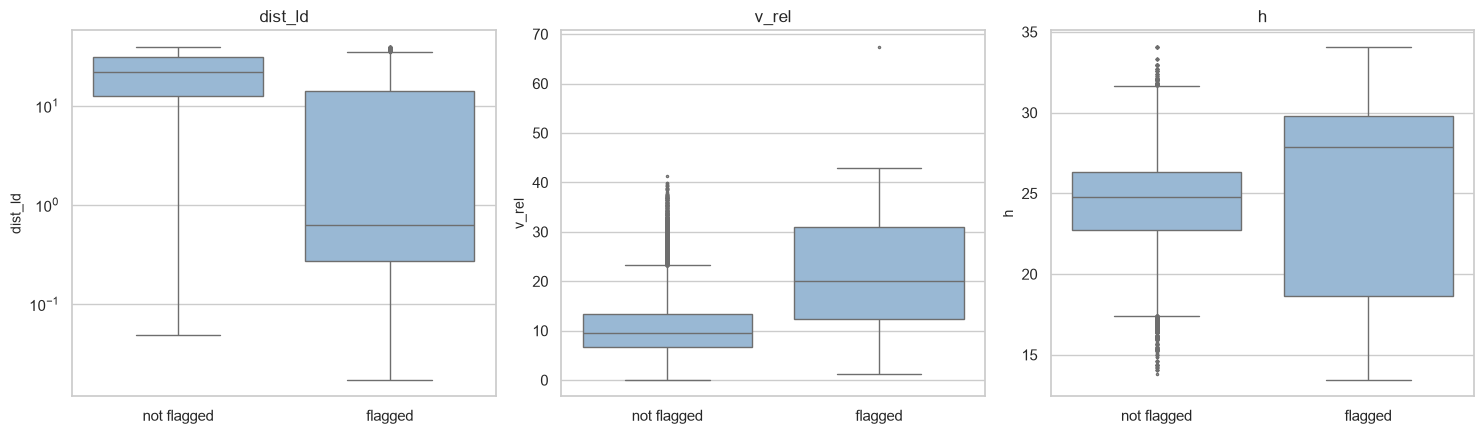

,contamination,flagged,jaccard_overlap_with_chosen
0,0.005,604,0.5
1,0.010,1207,1.0
2,0.020,2414,0.5


Flagged by Isolation Forest AND by an IQR fence (notebook 02): 1,044 of 1,207 flagged events


In [9]:
# Compare flagged vs not flagged events using medians.
compare = model_df.groupby("is_anomaly")[["dist_ld", "v_rel", "h"]].median().round(4)
compare["events"] = model_df.groupby("is_anomaly").size()
compare["share_with_diameter"] = model_df.groupby("is_anomaly")["has_diameter"].mean().round(4)
display(compare.rename(index={False: "not flagged", True: "flagged"}))

# Boxplots of the 3 features for flagged vs not flagged.
box_settings = [("dist_ld", True), ("v_rel", False), ("h", False)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i in range(len(box_settings)):
    col, use_log = box_settings[i]
    ax = axes[i]
    sns.boxplot(data=model_df, x="is_anomaly", y=col, ax=ax, color="#8FB8DE", fliersize=1.5)
    if use_log:
        ax.set_yscale("log")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["not flagged", "flagged"])
    ax.set_xlabel("")
    ax.set_title(col)
fig.tight_layout()
save_figure(fig, "03_anomaly_comparison")
plt.show()

# Sensitivity: how much does the flagged set change with 0.5%, 1%, 2% contamination?
# Jaccard overlap = |A and B| / |A or B| (1 = same set).
base_flags = model_df["is_anomaly"].to_numpy()
rows = []
for contamination in [0.005, 0.01, 0.02]:
    other_model = IsolationForest(n_estimators=200, contamination=contamination, random_state=RANDOM_SEED, n_jobs=-1).fit(X)
    other = other_model.predict(X) == -1
    inter = int((base_flags & other).sum())
    union = int((base_flags | other).sum())
    rows.append({"contamination": contamination, "flagged": int(other.sum()),
                 "jaccard_overlap_with_chosen": round(inter / union, 3)})
display(pd.DataFrame(rows))

# How many Isolation Forest anomalies are also IQR outliers from notebook 02?
if "iqr_outlier_v_rel" in model_df.columns:
    iqr_any = model_df[["iqr_outlier_dist_ld", "iqr_outlier_v_rel", "iqr_outlier_h"]].astype(bool).any(axis=1)
    print(f"Flagged by Isolation Forest AND by an IQR fence (notebook 02): "
          f"{int((model_df['is_anomaly'] & iqr_any).sum()):,} of {n_flag:,} flagged events")

> **Interpretation:**
> Isolation Forest flagged exactly **1,207** events (**1.00%**), directly matching the configured contamination threshold (0.01). Flagged anomalies differ starkly from nominal encounters:
> - **Distance:** Median of **0.58 LD** for anomalies (with 25% passing closer than 0.26 LD, well inside the Moon's orbit) versus **21.92 LD** for normal events.
> - **Velocity:** Median of **18.73 km/s** for anomalies versus **9.55 km/s** for normal events.
> - **Magnitude:** Median $H = 28.39$ for anomalies (small, faint meter-scale boulders) versus $24.80$ for normal events.
> - Anomaly status denotes multivariate rarity in feature space (e.g. ultra-close passes, exceptionally high velocity, or extreme faintness), not physical impact danger or telemetry errors.

## 5. Simple rule-based categories

No training: plain if/else rules from `src/features.py`. They are **not** risk levels.

| Column | Rule | Applies to |
|---|---|---|
| `proximity_class` | distance: <1 LD, 1-5 LD, 5-20 LD, ≥20 LD | Earth only |
| `velocity_class` | `v_rel`: <10, 10-20, ≥20 km/s | all |
| `size_class` | H ≤ 22, 22-26, > 26, or unknown | all |
| `exploratory_group` | A: <5 LD & H≤22; B: <5 LD & H>22; C: <5 LD & H unknown; D: Earth ≥5 LD; N/A: other bodies | all |

In [10]:
# Count of events in each category, for each of the 4 category columns.
for col in ["proximity_class", "velocity_class", "size_class", "exploratory_group"]:
    counts = events[col].value_counts(sort=False)
    table = pd.DataFrame({"events": counts, "share_%": (counts / len(events) * 100).round(2)})
    display(table.rename_axis(col))


# Helper functions for the 25th and 75th percentile (used inside agg below).
def q1(values):
    return values.quantile(0.25)


def q3(values):
    return values.quantile(0.75)


# Statistics per exploratory group.
group_stats = events.groupby("exploratory_group", observed=True).agg(
    events=("des", "size"),
    objects=("des", "nunique"),
    median_dist_ld=("dist_ld", "median"),
    median_v_rel=("v_rel", "median"),
    q1_v_rel=("v_rel", q1),
    q3_v_rel=("v_rel", q3),
    share_with_diameter=("has_diameter", "mean"),
)
display(group_stats.round(3))

# Cross table: proximity vs velocity class (with row/column totals).
display(pd.crosstab(events["proximity_class"], events["velocity_class"], margins=True))

,events,share_%
proximity_class,,
<1 LD,1769,0.74
1-5 LD,8485,3.56
5-20 LD,44171,18.51
>=20 LD,66351,27.81
N/A (non-Earth body),117794,49.38


,events,share_%
velocity_class,,
Slow (<10 km/s),94989,39.82
Moderate (10-20 km/s),101203,42.42
Fast (>=20 km/s),42378,17.76


,events,share_%
size_class,,
Larger (H<=22),70403,29.51
Medium (22<H<=26),107709,45.15
Small (H>26),60226,25.24
H unknown,232,0.10


,events,share_%
exploratory_group,,
A: <5 LD & larger (H<=22),391,0.16
B: <5 LD & medium/small (H>22),9862,4.13
C: <5 LD & H unknown,1,0.00
"D: Earth, >=5 LD",110522,46.33
N/A (non-Earth body),117794,49.38


,events,objects,median_dist_ld,median_v_rel,q1_v_rel,q3_v_rel,share_with_diameter
exploratory_group,,,,,,,
A: <5 LD & larger (H<=22),391,264,3.541,14.325,10.163,19.385,0.179
B: <5 LD & medium/small (H>22),9862,7330,2.646,9.559,6.942,12.988,0.003
C: <5 LD & H unknown,1,1,4.653,42.919,42.919,42.919,0.000
"D: Earth, >=5 LD",110522,25604,23.344,9.587,6.697,13.490,0.041
N/A (non-Earth body),117794,18208,25.672,14.560,9.780,21.524,0.062


velocity_class,Slow (<10 km/s),Moderate (10-20 km/s),Fast (>=20 km/s),All
proximity_class,,,,
<1 LD,795,852,122,1769
1-5 LD,4623,3474,388,8485
5-20 LD,24916,16885,2370,44171
>=20 LD,33832,27508,5011,66351
N/A (non-Earth body),30823,52484,34487,117794
All,94989,101203,42378,238570


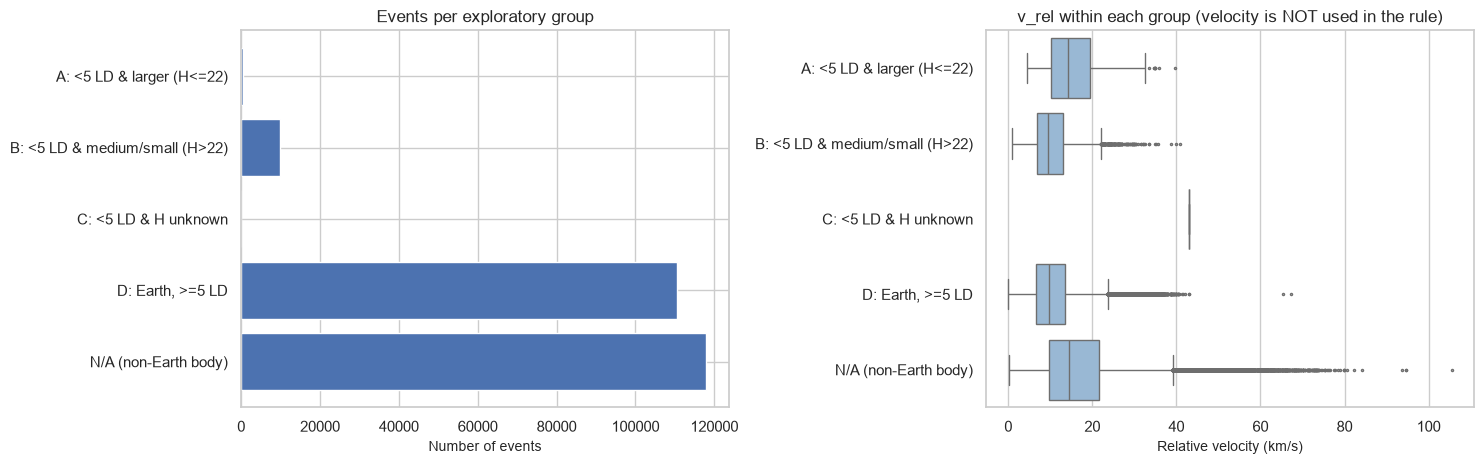

exploratory_group,A: <5 LD & larger (H<=22),B: <5 LD & medium/small (H>22),"D: Earth, >=5 LD"
cluster,,,
0,0.006,0.001,0.993
1,0.000,0.000,1.000
2,0.010,0.549,0.441


In [11]:
# Keep only group labels that appear in the data, in the defined order.
present_groups = set(events["exploratory_group"].astype(str))
order = []
for g in features.GROUP_LABELS.values():
    if g in present_groups:
        order.append(g)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Left: number of events per group (horizontal bars, first group on top).
counts = events["exploratory_group"].astype(str).value_counts().reindex(order)
axes[0].barh(counts.index[::-1], counts.values[::-1], color="#4C72B0")
axes[0].set_xlabel("Number of events")
axes[0].set_title("Events per exploratory group")

# Right: speed distribution inside each group.
plot_data = events.copy()
plot_data["group"] = plot_data["exploratory_group"].astype(str)
sns.boxplot(data=plot_data, y="group", x="v_rel", order=order, ax=axes[1], color="#8FB8DE", fliersize=1.5)
axes[1].set_xlabel("Relative velocity (km/s)")
axes[1].set_ylabel("")
axes[1].set_title("v_rel within each group (velocity is NOT used in the rule)")
fig.tight_layout()
save_figure(fig, "03_exploratory_groups")
plt.show()

# Do the data-driven clusters match the rule-based groups? (share of each group inside each cluster)
link = pd.crosstab(model_df["cluster"], model_df["exploratory_group"].astype(str), normalize="index").round(3)
display(link)

> **Interpretation:**
> The threshold-based exploratory categories partition Earth approaches as follows:
> - **Group D (Earth, $\ge 5$ LD):** 110,522 events (91.60%).
> - **Group B (Earth, $< 5$ LD, medium/small $H > 22$):** 9,862 events (8.17%).
> - **Group A (Earth, $< 5$ LD, larger $H \le 22$):** 391 events (0.32%).
> - **Group C (Earth, $< 5$ LD, $H$ unknown):** 1 event (< 0.01%).

> Comparison with K-Means shows strong structural alignment: **Cluster 2** captures 99.6% of Group B (9,819 events) and 47.6% of Group A (186 events), while Clusters 0 and 1 consist entirely of Group D distant passes. Limitations remain critical: the 5 LD and $H=22$ cutoffs are arbitrary conventions, $H$ is a proxy for optical brightness rather than mass, nominal distances exclude orbital covariance, and a close flyby implies zero impact probability.

## 6. Save headline numbers

In [12]:
# Convert numbers to plain Python types for JSON.
silhouette_by_k = {}
for k in k_table.index:
    silhouette_by_k[int(k)] = round(float(k_table.loc[k, "silhouette"]), 4)

cluster_counts = model_df["cluster"].value_counts().sort_index()
cluster_sizes = {}
for c in cluster_counts.index:
    cluster_sizes[int(c)] = int(cluster_counts[c])

group_value_counts = events["exploratory_group"].value_counts()
group_counts = {}
for g in group_value_counts.index:
    group_counts[str(g)] = int(group_value_counts[g])

# Read existing results (written by notebook 02), add the "ml" part, write back.
if RESULTS_PATH.exists():
    results = json.loads(RESULTS_PATH.read_text())
else:
    results = {}
results["ml"] = {
    "modelling_body": CLUSTER_BODY,
    "model_features": MODEL_FEATURES,
    "rows_used": int(len(model_df)),
    "rows_dropped_missing_features": int((~valid).sum()),
    "silhouette_by_k": silhouette_by_k,
    "k_used": int(K),
    "k_suggested_by_silhouette": suggested_k,
    "seed_stability_ari": round(float(ari), 4),
    "cluster_sizes": cluster_sizes,
    "isolation_forest": {"contamination": CONTAMINATION, "flagged": n_flag,
                         "flagged_pct": round(n_flag / len(model_df) * 100, 3)},
    "group_counts": group_counts,
}
RESULTS_PATH.write_text(json.dumps(results, indent=2))
print("Updated", RESULTS_PATH.relative_to(ROOT))

Updated reports\results_summary.json


## 7. Takeaways

1. **Clusters:** K-Means with $k=3$ (silhouette 0.355, ARI 0.995) reliably partitions Earth encounters into faint slow distant passes (55.4%), brighter fast distant passes (29.7%), and faint close passes (14.9%).
2. **Anomalies:** Isolation Forest (1% contamination, 1,207 flagged events) isolates extreme multivariate tail events characterized by ultra-close proximity (median 0.58 LD), elevated speed (median 18.7 km/s), and extreme faintness (median $H=28.39$).
3. **Categories:** Rule-based grouping shows that 91.6% of Earth encounters remain safely beyond 5 LD, while only 0.32% (391 events) represent larger asteroids ($H \le 22$) passing within 5 LD.

**Limitations.** Only 3 features; clusters depend on scaling, feature choice and k; Isolation Forest flags a fixed share by design; categories use arbitrary thresholds; nothing here estimates impact probability.

**References:** Liu, Ting & Zhou (2008), *Isolation Forest*, ICDM. Pedregosa et al. (2011), *Scikit-learn: Machine Learning in Python*, JMLR 12.